In [1]:
!pip install wordcloud langdetect nltk -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 15.7 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from nltk import ngrams
from collections import Counter
from langdetect import detect, DetectorFactory
from tqdm import tqdm
import re
import os
import warnings

warnings.filterwarnings('ignore')
DetectorFactory.seed = 42  # make langdetect deterministic

PLOTS_DIR = '/kaggle/working/plots'
os.makedirs(PLOTS_DIR, exist_ok=True)

LABEL_NAMES  = ['1 star', '2 stars', '3 stars', '4 stars', '5 stars']
CLASS_COLORS = sns.color_palette('RdYlGn', n_colors=5)

print('Imports OK')

Imports OK


In [3]:
DATA_DIR = '/kaggle/input/datasets/vladciuperceanu/sentiment-classification-data/data'

train_df = pd.read_csv(f'{DATA_DIR}/train.csv')
test_df  = pd.read_csv(f'{DATA_DIR}/test.csv')

print(f'Train: {len(train_df):,} rows')
print(f'Test:  {len(test_df):,} rows')
print(f'Columns: {train_df.columns.tolist()}')
train_df.head(5)

Train: 252,000 rows
Test:  168,000 rows
Columns: ['id', 'sentence', 'label']


,id,sentence,label
0,0,Moderner Weihnachtsbaum in weiß\n\nDieses Jahr...,4
1,1,Passt wie angegossen\n\nTasche kam schnell und...,4
2,2,Schlechte Qualität\n\nIch habe sehr lange auf ...,1
3,3,Bestellung nie angekommen\n\n-5 Sterne..... Am...,0
4,4,Für mich gar nicht gut\n\nMacht das Makeup gar...,1


In [4]:
print('=== Missing values ===')
print(train_df.isnull().sum())
print()
print('=== Label distribution (train) ===')
label_counts = train_df['label'].value_counts().sort_index()
label_pct    = (label_counts / len(train_df) * 100).round(2)
dist_df = pd.DataFrame({'count': label_counts, 'pct': label_pct})
dist_df.index = LABEL_NAMES
print(dist_df.to_string())

=== Missing values ===
id          0
sentence    0
label       0
dtype: int64

=== Label distribution (train) ===
         count   pct
1 star   50400  20.0
2 stars  50400  20.0
3 stars  50400  20.0
4 stars  50400  20.0
5 stars  50400  20.0


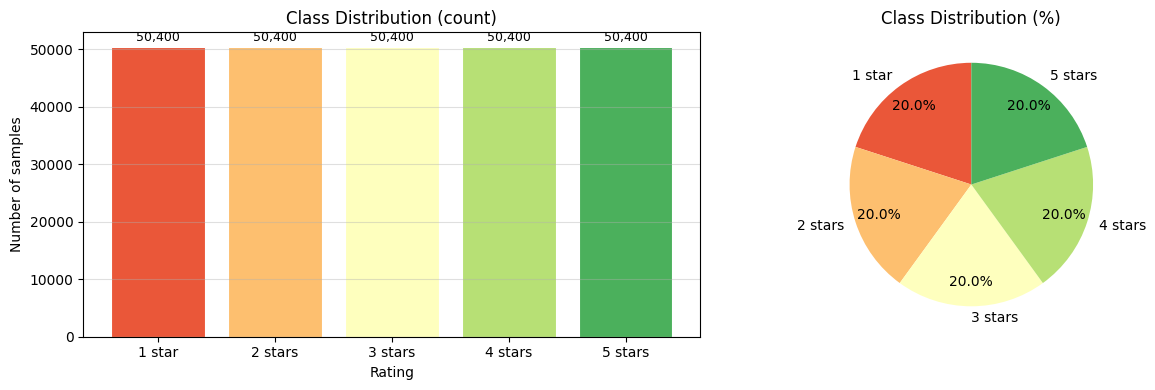

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

bars = axes[0].bar(LABEL_NAMES, label_counts.values, color=CLASS_COLORS, edgecolor='white', linewidth=0.8)
for bar, count in zip(bars, label_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'{count:,}', ha='center', va='bottom', fontsize=9)
axes[0].set_title('Class Distribution (count)', fontsize=12)
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Number of samples')
axes[0].grid(axis='y', alpha=0.4)

axes[1].pie(label_counts.values, labels=LABEL_NAMES, colors=CLASS_COLORS,
            autopct='%1.1f%%', startangle=90, pctdistance=0.8)
axes[1].set_title('Class Distribution (%)', fontsize=12)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [6]:
def detect_language(text):
    try:
        if not isinstance(text, str) or len(text.strip()) < 10:
            return 'unknown'
        return detect(text)
    except Exception:
        return 'unknown'

SAMPLE_SIZE = min(5000, len(train_df))
sample_df = train_df.sample(SAMPLE_SIZE, random_state=42).copy()

tqdm.pandas(desc='Detecting language')
sample_df['lang'] = sample_df['sentence'].progress_apply(detect_language)

print(f'Language distribution (sample of {SAMPLE_SIZE:,}):')
print(sample_df['lang'].value_counts().head(10).to_string())

Detecting language: 100%|██████████| 5000/5000 [00:13<00:00, 384.01it/s]

Language distribution (sample of 5,000):
lang
en    2509
de    2471
da       5
af       3
fr       2
no       2
cy       1
id       1
fi       1
nl       1


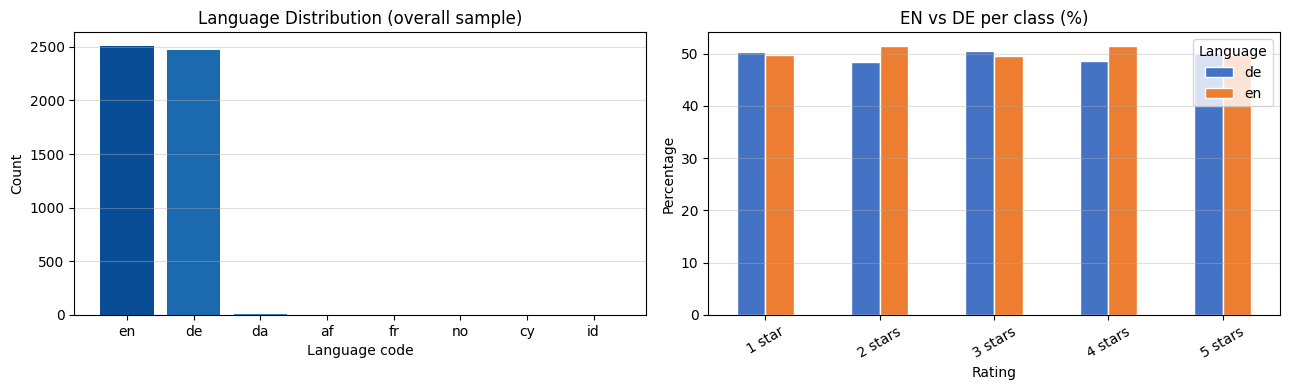

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

lang_counts = sample_df['lang'].value_counts().head(8)
axes[0].bar(lang_counts.index, lang_counts.values,
            color=sns.color_palette('Blues_r', n_colors=len(lang_counts)))
axes[0].set_title('Language Distribution (overall sample)', fontsize=12)
axes[0].set_xlabel('Language code')
axes[0].set_ylabel('Count')
axes[0].grid(axis='y', alpha=0.4)

lang_by_class = (
    sample_df[sample_df['lang'].isin(['en', 'de'])]
    .groupby(['label', 'lang']).size()
    .unstack(fill_value=0)
)
lang_by_class.index = [LABEL_NAMES[i] for i in lang_by_class.index]
lang_by_class_pct = lang_by_class.div(lang_by_class.sum(axis=1), axis=0) * 100
lang_by_class_pct.plot(kind='bar', ax=axes[1], color=['#4472C4', '#ED7D31'], edgecolor='white')
axes[1].set_title('EN vs DE per class (%)', fontsize=12)
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Percentage')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30)
axes[1].legend(title='Language')
axes[1].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/language_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
train_df['text_len_chars'] = train_df['sentence'].str.len()
train_df['text_len_words'] = train_df['sentence'].str.split().str.len()

print('=== Text length statistics ===')
print(train_df[['text_len_chars', 'text_len_words']].describe().round(1).to_string())
print()
print('=== Mean word count per class ===')
print(train_df.groupby('label')['text_len_words']
      .describe()[['mean','50%','max']]
      .rename(index=dict(enumerate(LABEL_NAMES)))
      .round(1).to_string())

=== Text length statistics ===
       text_len_chars  text_len_words
count        252000.0        252000.0
mean            218.4            37.5
std             187.8            32.7
min              18.0             2.0
25%              96.0            16.0
50%             168.0            28.0
75%             275.0            47.0
max            3845.0           737.0

=== Mean word count per class ===
         mean   50%    max
label                     
1 star   35.9  28.0  590.0
2 stars  41.8  33.0  567.0
3 stars  40.0  31.0  737.0
4 stars  38.2  28.0  588.0
5 stars  31.6  24.0  574.0


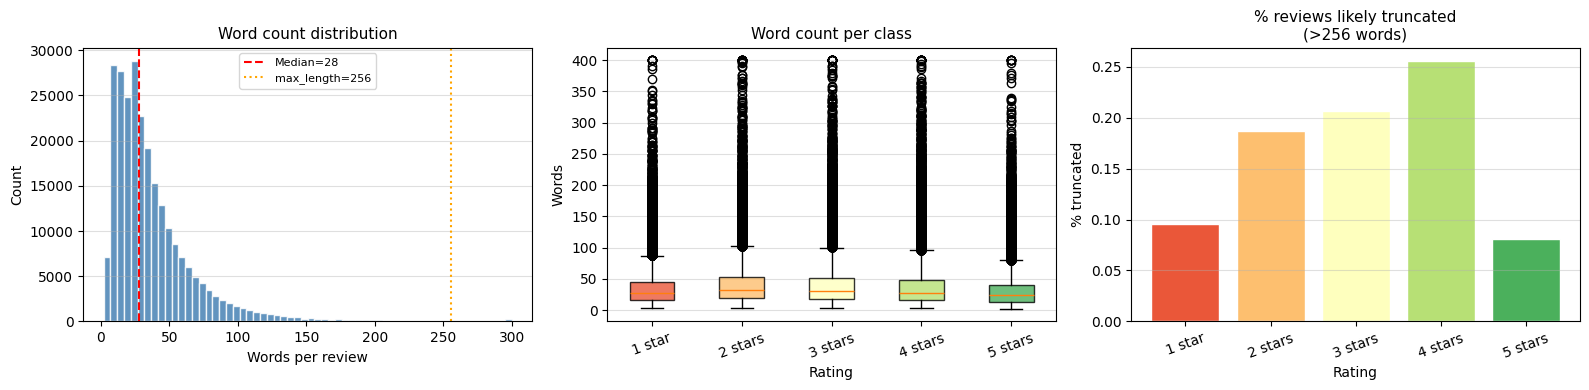

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(train_df['text_len_words'].clip(upper=300), bins=60,
             color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(train_df['text_len_words'].median(), color='red',
                linestyle='--', label=f'Median={train_df["text_len_words"].median():.0f}')
axes[0].axvline(256, color='orange', linestyle=':', label='max_length=256')
axes[0].set_title('Word count distribution', fontsize=11)
axes[0].set_xlabel('Words per review')
axes[0].set_ylabel('Count')
axes[0].legend(fontsize=8)
axes[0].grid(axis='y', alpha=0.4)

data_per_class = [train_df[train_df['label'] == c]['text_len_words'].clip(upper=400).values
                  for c in range(5)]
bp = axes[1].boxplot(data_per_class, labels=LABEL_NAMES, patch_artist=True)
for patch, color in zip(bp['boxes'], CLASS_COLORS):
    patch.set_facecolor(color); patch.set_alpha(0.8)
axes[1].set_title('Word count per class', fontsize=11)
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Words')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.4)

trunc_pct = train_df.groupby('label').apply(
    lambda df: (df['text_len_words'] > 256).mean() * 100)
axes[2].bar([LABEL_NAMES[i] for i in trunc_pct.index], trunc_pct.values,
            color=CLASS_COLORS, edgecolor='white')
axes[2].set_title('% reviews likely truncated\n(>256 words)', fontsize=11)
axes[2].set_xlabel('Rating')
axes[2].set_ylabel('% truncated')
axes[2].tick_params(axis='x', rotation=20)
axes[2].grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/text_length_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

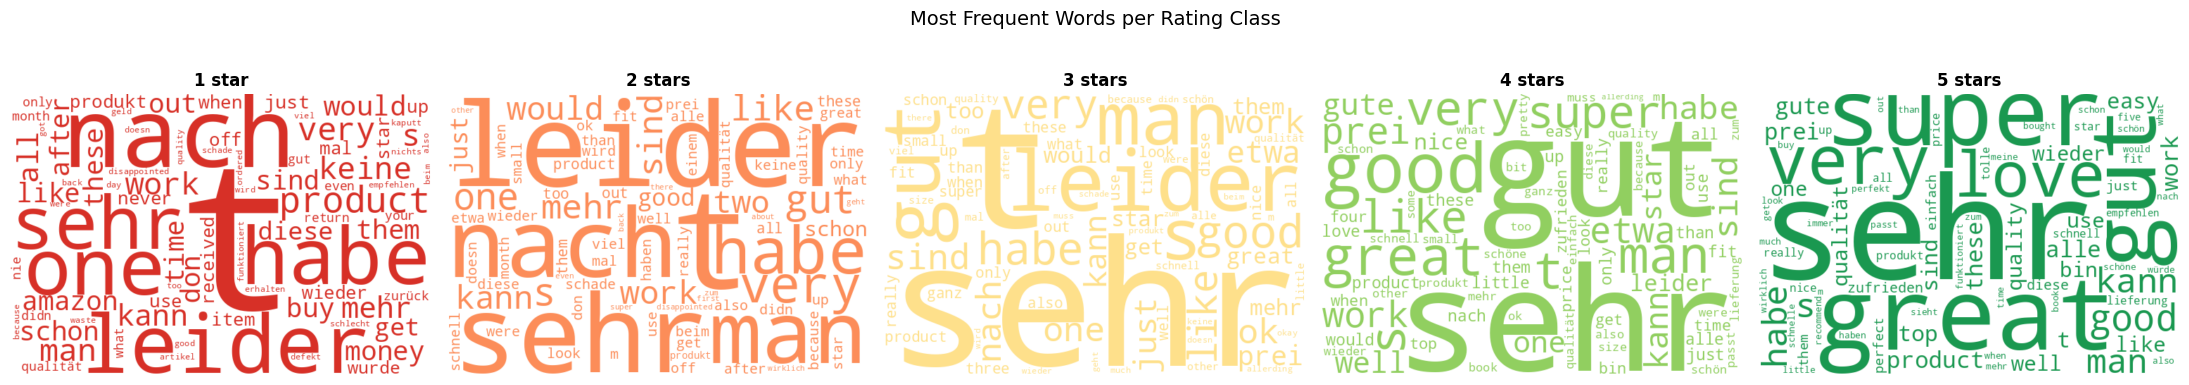

In [10]:
STOPWORDS_EN_DE = {
    # English
    'the','a','an','and','or','but','in','on','at','to','for','of','with',
    'is','it','this','that','was','are','be','has','have','had','not','as',
    'by','from','they','we','you','he','she','i','my','me','his','her',
    'our','their','its','so','if','can','will','do','did','does','no','more',
    # German
    'die','der','das','ein','eine','ist','ich','es','und','mit','nicht','sie',
    'auf','dem','des','den','von','zu','im','an','auch','als','bei','wie',
    'hat','er','war','aber','noch','am','aus','oder','um','da','dann','nur',
    'wenn','werden','sein','dass','für','wir','mir','mich','sich','einen','einer',
}

def get_class_text(df, label):
    texts = df[df['label'] == label]['sentence'].str.lower()
    texts = texts.apply(lambda t: re.sub(r'[^a-zäöüàáâãéèêëîïôùúûüçß\s]', ' ', t))
    return ' '.join(texts)

HEX_COLORS = ['#D73027', '#FC8D59', '#FEE08B', '#91CF60', '#1A9850']

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for label in range(5):
    text  = get_class_text(train_df, label)
    color = HEX_COLORS[label]
    wc = WordCloud(
        width=600, height=400,
        background_color='white',
        stopwords=STOPWORDS_EN_DE,
        max_words=80,
        color_func=lambda *args, **kwargs: color,
        prefer_horizontal=0.85,
        collocations=False,
    ).generate(text)
    axes[label].imshow(wc, interpolation='bilinear')
    axes[label].axis('off')
    axes[label].set_title(LABEL_NAMES[label], fontsize=12, fontweight='bold')

plt.suptitle('Most Frequent Words per Rating Class', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig(f'{PLOTS_DIR}/wordclouds_per_class.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
def get_top_ngrams(df, label, n, top_k=10, stopwords=STOPWORDS_EN_DE):
    texts = df[df['label'] == label]['sentence'].str.lower()
    texts = texts.apply(lambda t: re.sub(r'[^a-zäöüàáâãéèêëîïôùúûüçß\s]', ' ', t))
    tokens_list  = [t.split() for t in texts]
    all_ngrams   = [
        ng for tokens in tokens_list
        for ng in ngrams(tokens, n)
        if not any(w in stopwords for w in ng)
    ]
    return Counter(all_ngrams).most_common(top_k)

def plot_ngrams_grid(df, n, top_k=10, title_prefix='Bigrams'):
    fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=False)
    palette   = sns.color_palette('RdYlGn', n_colors=5)
    for label in range(5):
        top = get_top_ngrams(df, label, n, top_k)
        if not top:
            axes[label].set_visible(False)
            continue
        ng_labels = [' '.join(ng) for ng, _ in top]
        counts    = [c for _, c in top]
        axes[label].barh(ng_labels[::-1], counts[::-1],
                         color=palette[label], edgecolor='white', alpha=0.9)
        axes[label].set_title(LABEL_NAMES[label], fontsize=11, fontweight='bold')
        axes[label].set_xlabel('Frequency')
        axes[label].grid(axis='x', alpha=0.4)
        axes[label].tick_params(axis='y', labelsize=8)
    plt.suptitle(f'Top {top_k} {title_prefix} per Rating Class', fontsize=13, y=1.01)
    plt.tight_layout()
    fname = title_prefix.lower().replace(' ', '_')
    plt.savefig(f'{PLOTS_DIR}/{fname}_per_class.png', dpi=150, bbox_inches='tight')
    plt.show()

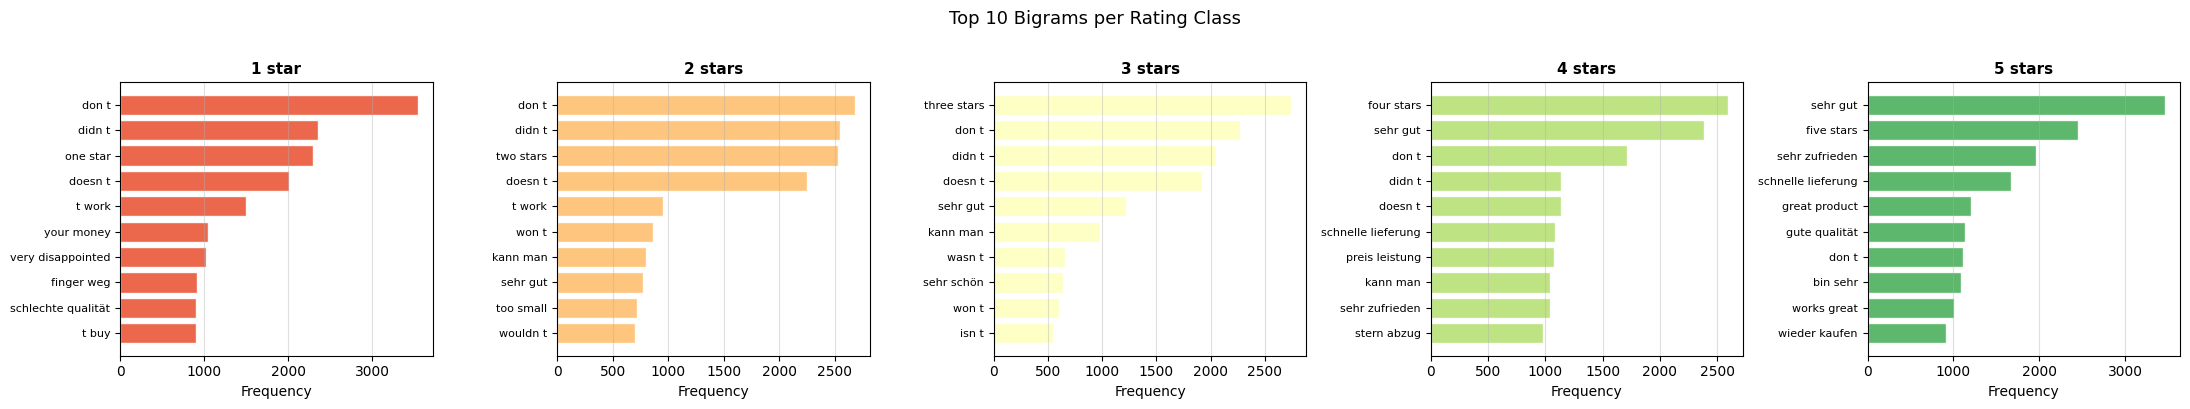

In [12]:
plot_ngrams_grid(train_df, n=2, top_k=10, title_prefix='Bigrams')

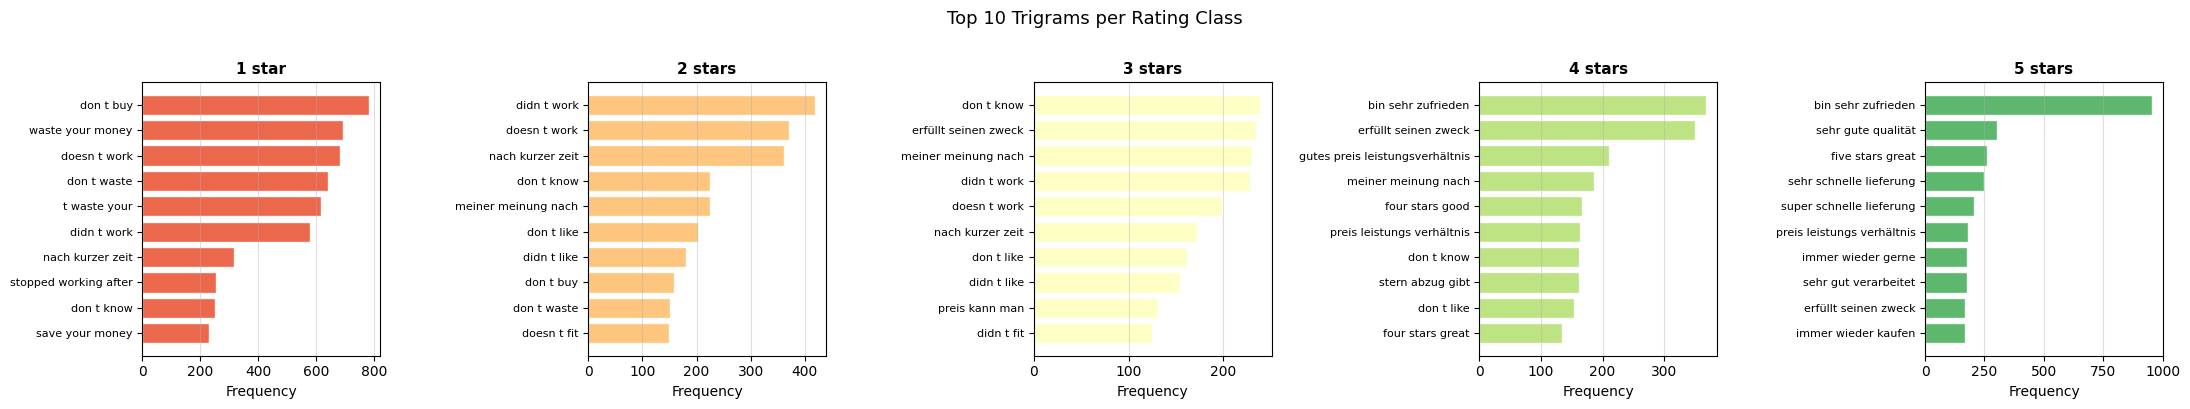

In [13]:
plot_ngrams_grid(train_df, n=3, top_k=10, title_prefix='Trigrams')

In [14]:
STRONG_POSITIVE = {
    # EN
    'excellent','amazing','outstanding','perfect','fantastic','wonderful',
    'superb','great','love','loved','brilliant','incredible','awesome',
    'best','highly recommend',
    # DE
    'ausgezeichnet','perfekt','fantastisch','hervorragend','wunderbar',
    'toll','super','sehr gut','empfehle','empfehlenswert','begeistert',
}
STRONG_NEGATIVE = {
    # EN
    'terrible','horrible','awful','worst','disgusting','useless','waste',
    'broken','defective','hate','disappointed','disappointing',
    'never again','do not buy','rubbish','garbage','scam','fraud',
    # DE
    'schrecklich','furchtbar','schlecht','enttäuschend','defekt','kaputt',
    'nutzlos','nie wieder','katastrophe','betrug','müll',
}

def contains_any(text, keywords):
    text_lower = text.lower()
    return any(kw in text_lower for kw in keywords)

# 1-star review but text has positive signals only
suspicious_pos_in_neg = train_df[
    (train_df['label'] == 0) &
    train_df['sentence'].apply(lambda t: contains_any(t, STRONG_POSITIVE)) &
    ~train_df['sentence'].apply(lambda t: contains_any(t, STRONG_NEGATIVE))
]

# 5-star review but text has negative signals only
suspicious_neg_in_pos = train_df[
    (train_df['label'] == 4) &
    train_df['sentence'].apply(lambda t: contains_any(t, STRONG_NEGATIVE)) &
    ~train_df['sentence'].apply(lambda t: contains_any(t, STRONG_POSITIVE))
]

total_flagged = len(suspicious_pos_in_neg) + len(suspicious_neg_in_pos)
print(f'1-star reviews with positive keywords only : {len(suspicious_pos_in_neg):,}')
print(f'5-star reviews with negative keywords only : {len(suspicious_neg_in_pos):,}')
print(f'Total flagged : {total_flagged:,}  ({total_flagged / len(train_df) * 100:.2f}% of train)')

1-star reviews with positive keywords only : 5,972
5-star reviews with negative keywords only : 303
Total flagged : 6,275  (2.49% of train)


In [15]:
pd.set_option('display.max_colwidth', 200)

print('=== 1-star reviews with positive text (first 5) ===')
display(suspicious_pos_in_neg[['sentence','label']].head(5))

print()
print('=== 5-star reviews with negative text (first 5) ===')
display(suspicious_neg_in_pos[['sentence','label']].head(5))

=== 1-star reviews with positive text (first 5) ===


,sentence,label
3,Bestellung nie angekommen\n\n-5 Sterne..... Am 15.5 bestellt und bis jetzt immer noch nicht da. Das Teil können Sie behalten,0
21,"Habe meine Bestellung noch nicht erhalten\n\nWarte seit 19.06 auf meine Bestellung,ich hoffe das die noch dieses Jahr eintrifft.",0
22,Works well\n\nPerfect for shaving. Holds all the hair so it doesn’t go everywhere. Holds onto the mirror well and does it’s job,0
25,Leider gibt es keine minus Sterne.\n\nKann ich nicht weiter empfehlen. Sind nie angekommen.,0
47,"Quit working in 30 days\n\nQuit working exactly 30 days from purchase. It was working great, then we came home and the tank was over 120 degrees. Wouldn't shut off. Our Gecko was hiding under a ro...",0



=== 5-star reviews with negative text (first 5) ===


,sentence,label
410,"Ein Herz im Regen!\n\nWirklich, die Dame, der ich diesen Schirm am Valentinstag geschenkt hat, wird diesen Moment nie wieder vergessen!",4
471,Fun and Colorful\n\nOverall this is a good item. It is obviously plastic and plastic breaks down overtime. I don't imagine these will be any different. It took me a minute to figure out how to ope...,4
1126,Ersatz für Kärcher!\n\nHab den Motor in einen Kärcher waschsauger eingebaut ( mit etwas gebastel) da der originale Kurz nach der Garantie defekt war. Und Kärcher dafür 140€ will. Der Motor ist wes...,4
1334,"Top Arikel\n\nQualität und Anbringung der Artikel ist gut. Für den Preis das ideale Paket für jeden Spark Besitzer der seine Drohne mittransportiert oder lieber alles sicher und geschützt hat, sod...",4
1864,Hat seinen Zweck schon bewiesen\n\nHabe mehrere Displayschutzfolien fürs S8 plus ausprobiert. Bisher hatte mich keine überzeugt. Auch bei dem Panzerglas von Artwizz war ich Anfangs skeptisch. Sie ...,4


In [16]:
short_reviews = train_df[train_df['text_len_words'] <= 3]
print(f'Reviews with ≤3 words: {len(short_reviews):,} ({len(short_reviews)/len(train_df)*100:.2f}%)')
print()
print('Distribution by class:')
print(short_reviews['label'].value_counts()
      .sort_index()
      .rename(index=dict(enumerate(LABEL_NAMES)))
      .to_string())
print()
print('Examples:')
display(short_reviews[['sentence','label']].sample(min(10, len(short_reviews)), random_state=42))

Reviews with ≤3 words: 104 (0.04%)

Distribution by class:
label
1 star     16
2 stars     4
3 stars    17
4 stars    28
5 stars    39

Examples:


,sentence,label
68712,GUT\n\nKeinerlei Beanstandungen,3
158231,Perfekt\n\nWie beschrieben...super,4
155606,Ok\n\nPreis-Leistungsverhältnis ok,2
139996,Zufrieden\n\nPreis/Leistung perfekt,3
116114,Schlecht\n\nSchlechte verarbeitung,0
217121,Super\n\nFunktioniert einwandfrei,4
214067,wirkungslos\n\nrausgeschmissenes Geld,0
117081,Ok\n\nFunktioniert einwandfrei!,3
36220,Uhr\n\nWurde zurückgesendet...,3
6309,useless\n\ncompletely ineffective.,0


In [17]:
checks = {
    'HTML tags'            : train_df['sentence'].str.contains(r'<[^>]+>', regex=True, na=False),
    'URLs'                 : train_df['sentence'].str.contains(r'https?://', regex=True, na=False),
    'Email addresses'      : train_df['sentence'].str.contains(r'\S+@\S+\.\S+', regex=True, na=False),
    'Digits only'          : train_df['sentence'].str.match(r'^\s*\d+\s*$', na=False),
    'ALL CAPS (>5 chars)'  : train_df['sentence'].apply(lambda t: isinstance(t,str) and t.isupper() and len(t)>5),
    'Multiple spaces'      : train_df['sentence'].str.contains(r'  +', regex=True, na=False),
    'Empty / NaN'          : train_df['sentence'].isna() | (train_df['sentence'].str.strip() == ''),
    'Duplicate sentences'  : train_df.duplicated(subset='sentence'),
}

print('=== Preprocessing Issues ===')
for issue, mask in checks.items():
    n   = mask.sum()
    pct = n / len(train_df) * 100
    status = '✓' if n == 0 else '⚠'
    print(f'{status}  {issue:<30}: {n:>7,}  ({pct:.3f}%)')

=== Preprocessing Issues ===
⚠  HTML tags                     :       6  (0.002%)
⚠  URLs                          :       4  (0.002%)
✓  Email addresses               :       0  (0.000%)
✓  Digits only                   :       0  (0.000%)
⚠  ALL CAPS (>5 chars)           :     331  (0.131%)
✓  Multiple spaces               :       0  (0.000%)
✓  Empty / NaN                   :       0  (0.000%)
⚠  Duplicate sentences           :      82  (0.033%)


In [18]:
dupes = train_df[train_df.duplicated(subset='sentence', keep=False)]
if len(dupes) > 0:
    print(f'Total duplicate sentences: {len(dupes):,}')
    conflicts = (
        dupes.groupby('sentence')['label']
        .nunique().gt(1).sum()
    )
    print(f'  → with conflicting labels (same text, different rating): {conflicts:,}')
    print(f'  → with same label: {dupes.groupby("sentence").ngroups - conflicts:,}')
    print()
    print('Sample conflicting duplicates:')
    conflict_texts = (
        dupes.groupby('sentence')['label']
        .nunique()[lambda s: s > 1]
        .index[:3]
    )
    for txt in conflict_texts:
        print(f'Text: {txt[:150]}')
        print(f'Labels: {dupes[dupes["sentence"]==txt]["label"].tolist()}')
        print()
else:
    print('No duplicate sentences found.')

Total duplicate sentences: 150
  → with conflicting labels (same text, different rating): 7
  → with same label: 61

Sample conflicting duplicates:
Text: Erfüllt seinen Zweck

Erfüllt seinen Zweck
Labels: [3, 2]

Text: Gut

Erfüllt seinen Zweck
Labels: [4, 3, 3]

Text: Keine Rechnung erhalten

Keine Rechnung erhalten
Labels: [0, 3]



In [19]:
print('=' * 55)
print('DATASET SUMMARY')
print('=' * 55)
print(f'Train samples        : {len(train_df):>10,}')
print(f'Test samples         : {len(test_df):>10,}')
print(f'Number of classes    : {5:>10}')
print(f'Median review length : {train_df["text_len_words"].median():>10.0f} words')
print(f'Mean review length   : {train_df["text_len_words"].mean():>10.1f} words')
print(f'Max review length    : {train_df["text_len_words"].max():>10,} words')
print(f'Reviews > 256 words  : {(train_df["text_len_words"] > 256).sum():>10,}  ({(train_df["text_len_words"] > 256).mean()*100:.1f}%)')
max_cls = label_counts.max()
min_cls = label_counts.min()
print(f'Imbalance ratio (max/min): {max_cls/min_cls:.2f}x')
print()
print('Per-class counts:')
for i, name in enumerate(LABEL_NAMES):
    n = label_counts[i]
    print(f'  {name}: {n:>8,}  ({n/len(train_df)*100:.1f}%)')

DATASET SUMMARY
Train samples        :    252,000
Test samples         :    168,000
Number of classes    :          5
Median review length :         28 words
Mean review length   :       37.5 words
Max review length    :        737 words
Reviews > 256 words  :        416  (0.2%)
Imbalance ratio (max/min): 1.00x

Per-class counts:
  1 star:   50,400  (20.0%)
  2 stars:   50,400  (20.0%)
  3 stars:   50,400  (20.0%)
  4 stars:   50,400  (20.0%)
  5 stars:   50,400  (20.0%)
